# Exercitiu laborator 8

In [1]:
import pymc as pm
import arviz as az
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

az.style.use('arviz-darkgrid')

## 1. Calculul distributiei a posteriori cu PyMC

Deoarece $n$ este o variabila aleatoare discreta (distributie Poisson), PyMC va folosi automat un sampler adecvat pentru variabile discrete (Metropolis). Pentru a evita erori de initializare in cazul in care $n < Y$, setam explicit `initval=max(10, y_obs)`.

In [5]:
import pytensor


Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]
lambda_prior = 10

traces = {}
summary_rows = []

for y_obs in Y_values:
    for theta in theta_values:
        with pm.Model() as model:
            n = pm.Poisson('n', mu=lambda_prior, initval=max(lambda_prior, y_obs))
            Y = pm.Binomial('Y', n=n, p=theta, observed=y_obs)
            
            pytensor.config.cxx = ""

            trace = pm.sample(
                draws=3000,
                tune=1000,
                chains=2,
                random_seed=42,
                progressbar=False
            )
            
        traces[(y_obs, theta)] = trace
        
        samples_n = trace.posterior['n'].values.flatten()
        mean_sim = np.mean(samples_n)
        sd_sim = np.std(samples_n)
        mean_teo = y_obs + lambda_prior * (1 - theta)
        sd_teo = np.sqrt(lambda_prior * (1 - theta))
        
        summary_rows.append({
            'Y': y_obs,
            'theta': theta,
            'Media_PyMC': round(mean_sim, 2),
            'Media_Teoretica': round(mean_teo, 2),
            'SD_PyMC': round(sd_sim, 2),
            'SD_Teoretica': round(sd_teo, 2)
        })

df_summary = pd.DataFrame(summary_rows)
df_summary

Multiprocess sampling (2 chains in 2 jobs)
Metropolis: [n]
Sampling 2 chains for 1_000 tune and 3_000 draw iterations (2_000 + 6_000 draws total) took 9 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Multiprocess sampling (2 chains in 2 jobs)
Metropolis: [n]
Sampling 2 chains for 1_000 tune and 3_000 draw iterations (2_000 + 6_000 draws total) took 10 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Multiprocess sampling (2 chains in 2 jobs)
Metropolis: [n]
Sampling 2 chains for 1_000 tune and 3_000 draw iterations (2_000 + 6_000 draws total) took 9 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Multiprocess sampling (2 chains in 2 jobs)
Metropolis: [n]
Sampling 2 chains for 1_000 tune and 3_000 draw iterations (2_000 + 6_000 draws total) took 9 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnos

,Y,theta,Media_PyMC,Media_Teoretica,SD_PyMC,SD_Teoretica
0,0,0.2,8.19,8.0,2.93,2.83
1,0,0.5,5.07,5.0,2.25,2.24
2,5,0.2,13.14,13.0,2.95,2.83
3,5,0.5,10.07,10.0,2.25,2.24
4,10,0.2,18.19,18.0,2.93,2.83
5,10,0.5,15.07,15.0,2.25,2.24


C:\Users\HP\AppData\Local\Temp\ipykernel_9136\3045177882.py:17: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


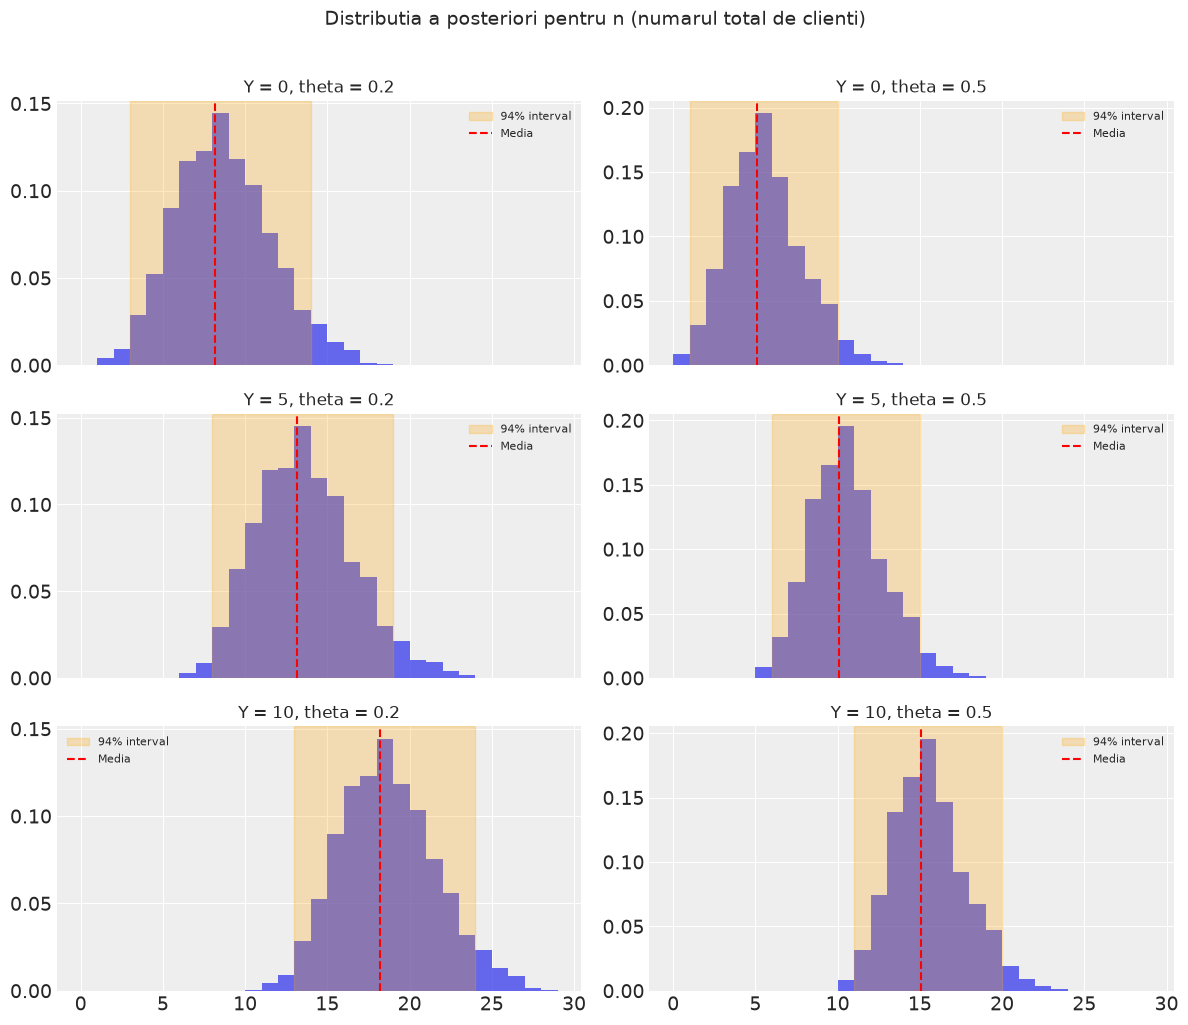

In [7]:
fig, axes = plt.subplots(len(Y_values), len(theta_values), figsize=(12, 10), sharex=True)

for i, y_obs in enumerate(Y_values):
    for j, theta in enumerate(theta_values):
        ax = axes[i, j]
        samples = traces[(y_obs, theta)].posterior['n'].values.flatten()
        lower, upper = np.quantile(samples, [0.03, 0.97])

        ax.hist(samples, bins='auto', density=True, alpha=0.7)
        ax.axvspan(lower, upper, color='orange', alpha=0.25, label='94% interval')
        ax.axvline(np.mean(samples), color='red', linestyle='--', label='Media')

        ax.set_title(f'Y = {y_obs}, theta = {theta}', fontsize=12)
        ax.legend(fontsize=8)

fig.suptitle('Distributia a posteriori pentru n (numarul total de clienti)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 2. Explicatia efectului lui $Y$ si $\theta$ asupra distributiei a posteriori

### Perspectiva analitica
Avand distributia a priori $n \sim \text{Poisson}(\lambda)$ cu $\lambda = 10$ si verosimilitatea $Y \mid n \sim \text{Binomial}(n, \theta)$, distributia a posteriori se poate deduce exact:

$$P(n \mid Y = y, \theta) \propto P(Y = y \mid n, \theta) P(n) = \binom{n}{y} \theta^y (1-\theta)^{n-y} \cdot \frac{\lambda^n e^{-\lambda}}{n!} \propto \frac{(\lambda(1-\theta))^{n-y}}{(n-y)!}, \quad n \ge y$$

Notand cu $k = n - Y$ numarul de clienti care **nu** au cumparat produsul, obtinem ca:
$$k \mid (Y, \theta) \sim \text{Poisson}(\lambda(1 - \theta))$$

Prin urmare, distributia a posteriori pentru $n$ este o distributie Poisson deplasata cu $Y$, avand:
- **Media a posteriori:** $E[n \mid Y, \theta] = Y + 10(1 - \theta)$
- **Varianta a posteriori:** $\text{Var}(n \mid Y, \theta) = 10(1 - \theta)$
- **Conditia de suport:** $n \ge Y$ (nu pot exista mai putini vizitatori totali decat cumparatori).

---

### Efectul lui $Y$ (numarul observat de clienti care au cumparat)
1. **Deplasarea distributiei spre dreapta (cresterea mediei):** Pe masura ce $Y$ creste ($0 \to 5 \to 10$), distributia a posteriori se deplaseaza direct proportional spre valori mai mari ale lui $n$. Media creste exact cu valoarea lui $Y$, iar limita inferioara a distributiei devine $Y$.
2. **Intuitie:** Daca observam mai multi clienti care au cumparat produsul, atunci numarul total de clienti care au intrat in magazin trebuie sa fie cel putin $Y$, la care se adauga estimarea pentru clientii care nu au cumparat.
3. **Incertitudinea (dispersia):** Pentru un $\theta$ fix, varianta ($10(1-\theta)$) si latimea intervalului HDI raman practic **neschimbate** indiferent de $Y$, deoarece singura parte necunoscuta ramane numarul de clienti care nu au cumparat.

---

### Efectul lui $\theta$ (probabilitatea de cumparare)
1. **Scaderea mediei a posteriori:** Pe masura ce $\theta$ creste (de la $0.2$ la $0.5$), media a posteriori pentru $n$ **scade** (cu $10 \cdot (0.5 - 0.2) = 3$ unitati pentru acelasi $Y$).
   - Exemplu pentru $Y = 5$: media scade de la $13$ (pentru $\theta = 0.2$) la $10$ (pentru $\theta = 0.5$).
   - Exemplu pentru $Y = 10$: media scade de la $18$ (pentru $\theta = 0.2$) la $15$ (pentru $\theta = 0.5$).
2. **Intuitie:** Daca probabilitatea ca un vizitator sa cumpere este mica ($\theta = 0.2$), atunci pentru a ajunge la $Y$ cumparatori a fost nevoie de multi vizitatori totali (multi au plecat fara sa cumpere). Daca $\theta = 0.5$, fiecare vizitator are sanse mai mari sa cumpere, deci un numar total mai mic de vizitatori explica aceeasi observatie $Y$.
3. **Reducerea incertitudinii (distributie mai ingusta):** Odata cu cresterea lui $\theta$, varianta scade ($8$ pentru $\theta = 0.2$ fata de $5$ pentru $\theta = 0.5$), deci intervalul HDI devine mai ingust. Cu cat $\theta$ este mai mare, cu atat valoarea observata $Y$ ne ofera mai multa informatie despre numarul total $n$ (in cazul extrem $\theta = 1$, am sti exact ca $n = Y$, fara incertitudine).

---

### Tabel rezumativ al celor 6 scenarii

| $Y$ | $\theta$ | Distributie $n - Y$ | Media teoretica $E[n \mid Y, \theta]$ | Deviatia standard $\sigma$ |
| :---: | :---: | :---: | :---: | :---: |
| 0 | 0.2 | Poisson(8) | 8.0 | 2.83 |
| 0 | 0.5 | Poisson(5) | 5.0 | 2.24 |
| 5 | 0.2 | Poisson(8) | 13.0 | 2.83 |
| 5 | 0.5 | Poisson(5) | 10.0 | 2.24 |
| 10 | 0.2 | Poisson(8) | 18.0 | 2.83 |
| 10 | 0.5 | Poisson(5) | 15.0 | 2.24 |